# Benchmark: TDVP wall time against N and h

Wall time of one TDVP run (`compare_with_exact`: RK45, `dt = 1e-3`, dense Jacobian QGT, `diag_shift = 1e-6`, `FullSumState`, RBM $\alpha = 1$) for N = 4, 6, 8 and three fields. Each N is run once first to exclude JAX compilation from the timings, and runs are sequential, so nothing else competes for the CPU.

The `tstops` grid caps every step at `dt`, so a run makes at least `T / dt` RK45 steps whatever $h$ is; the cost per grid step is the useful number. The exact evolution (`expm_multiply`) on the same grid is timed for scale.

In [1]:
import time

import numpy as np
from IPython.display import Image, display

from QELM.NQS.dynamics import (
    BASELINE_SEED,
    TDVPSettings,
    compare_with_exact,
    exact_time_evolution,
    time_grid,
)
from QELM.NQS.measurements import all_to_all_xx_hamiltonian
from QELM.NQS.paths import experiment_paths
from QELM.NQS.utils.makeplots import plot_field_scan
from QELM.NQS.utils.outputs import find_repo_root
from QELM.NQS.variational import rbm, spin_half_hilbert, variational_state

ROOT = find_repo_root()
SIZES = (4, 6, 8)
FIELDS = (0.1, 1.0, 10.0)
T_BENCH = 0.2
DT = 1e-3
SEED = BASELINE_SEED
SETTINGS = TDVPSettings(dt=DT, integrator="RK45", diag_shift=1e-6, linear_solver="svd")
n_steps = round(T_BENCH / DT)
paths = experiment_paths(
    experiment_name="tdvp_benchmark", outputs_root=ROOT / "outputs"
)

/home/claude/QRC-issue23/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


∣NK⟩ Tip: Save/load MCStates with `nqxpack.save({'state': vstate}, 'myfile')` and `.load('myfile.nk')`.

In [2]:
tdvp_time: dict[int, np.ndarray] = {}
ed_time: dict[int, float] = {}
for n in SIZES:
    compare_with_exact(
        n_spins=n, h=1.0, T=0.01, seed=SEED, settings=SETTINGS
    )  # warm-up
    tdvp_time[n] = np.asarray(
        [
            compare_with_exact(
                n_spins=n, h=h, T=T_BENCH, seed=SEED, settings=SETTINGS
            ).wall_time
            for h in FIELDS
        ]
    )
    hilbert = spin_half_hilbert(n)
    H = all_to_all_xx_hamiltonian(hilbert, h=1.0)
    psi0 = np.asarray(variational_state(hilbert, rbm(), seed=SEED).to_array())
    start = time.perf_counter()
    exact_time_evolution(H, psi0, time_grid(T_BENCH, DT))
    ed_time[n] = time.perf_counter() - start
    per_step = 1e3 * tdvp_time[n] / n_steps
    print(
        f"N={n}: TDVP {per_step.min():.0f}-{per_step.max():.0f} ms per step, "
        f"ED {1e3 * ed_time[n]:.1f} ms for the whole grid"
    )

N=4: TDVP 39-46 ms per step, ED 82.6 ms for the whole grid


N=6: TDVP 46-46 ms per step, ED 128.7 ms for the whole grid


N=8: TDVP 113-127 ms per step, ED 203.3 ms for the whole grid


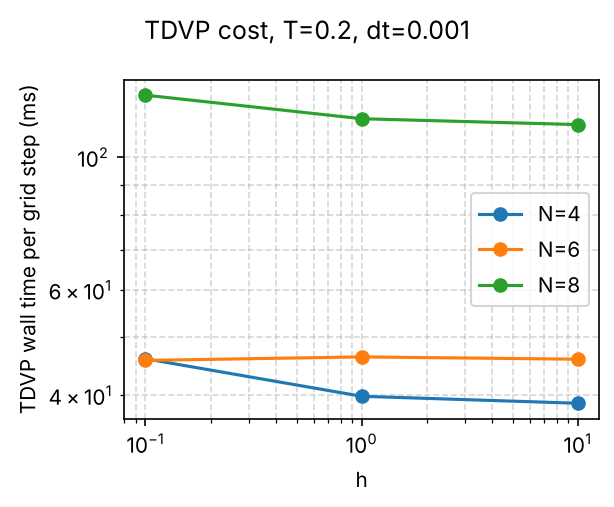

In [3]:
figure = plot_field_scan(
    {f"N={n}": np.asarray(FIELDS) for n in SIZES},
    {f"N={n}": {"per_step": 1e3 * tdvp_time[n] / n_steps} for n in SIZES},
    panels={"per_step": "TDVP wall time per grid step (ms)"},
    filename="tdvp_wall_time.png",
    directory=paths.plots,
    title=f"TDVP cost, T={T_BENCH:g}, dt={DT:g}",
)
display(Image(filename=str(figure)))